# 06 · Resultados: métricas y estadística

**Qué hace:** con las predicciones del cuaderno 05 calcula las métricas de D-14 y las pruebas de D-15, y escribe las tablas y figuras que van al informe en `resultados/`.

**Decisiones que aplica:** D-14 (MAE principal, RMSE, MASE, WAPE, sesgo, cobertura P90, pinball 0,9; sin MAPE), D-15 (unidad de análisis = el punto de corte; Diebold-Mariano con corrección de Harvey-Leybourne-Newbold y Holm por plato; Wilcoxon global sobre los pares plato × corte; diferencia de MAE con IC bootstrap del 95 %; α = 0,05 unilateral), D-09 (baselines), D-20 (ÁUREA es sintético: sus métricas solo muestran que el modelo recupera un patrón conocido).

**Escenario operativo:** `h` de 2 a 8 (el núcleo decide con los datos de ayer). `h = 1` va aparte. Las pruebas usan solo el escenario operativo: cada corte aporta 7 días, y cortes consecutivos no se solapan.

**Convención de signo:** `diferencia = MAE del comparador − MAE del modelo`. Positiva: el modelo se equivoca menos.

**Necesita:** `salidas/<fuente>/predicciones.parquet` (05). **Deja:** `resultados/tablas/` (CSV y Markdown) y `resultados/figuras/` (PNG).

In [1]:
# Parámetros
import json
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "cuadernos" else Path.cwd()
TABLAS, FIGURAS = RAIZ / "resultados" / "tablas", RAIZ / "resultados" / "figuras"
TABLAS.mkdir(parents=True, exist_ok=True); FIGURAS.mkdir(parents=True, exist_ok=True)
FUENTES = ["stuttgart", "aurea"]
H_OP = (2, 8)
ALFA = 0.05
N_BOOT, SEMILLA = 10_000, 2026
DECIMALES = 4

In [2]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Predictores (P50): el color sigue a la entidad, no a su rango. Paleta validada (3 espacios, todos los pares).
PREDICTORES = {"modelo": ("p50", "#2a78d6", "Modelo"),
               "ingenuo": ("ingenuo", "#eb6834", "Ingenuo estacional"),
               "media4": ("media4", "#1baf7a", "Media del mismo día (4)")}
P90 = {"modelo": "p90", "ingenuo": "p90_baseline", "media4": "p90_baseline"}   # los dos baselines comparten el P90 de D-09

D = {}
for f in FUENTES:
    d = RAIZ / "salidas" / f
    pred = pd.read_parquet(d / "predicciones.parquet")
    hist = pd.read_parquet(d / "historial.parquet")
    cal = json.loads((d / "calendario.json").read_text(encoding="utf-8"))
    meta = json.loads((d / "predicciones_meta.json").read_text(encoding="utf-8"))
    nombres = ({p: v["nombre"] for p, v in json.loads((d / "productos.json").read_text(encoding="utf-8")).items()}
               if (d / "productos.json").exists() else {})
    D[f] = dict(pred=pred, hist=hist, cal=cal, meta=meta, nombres=nombres)
    print(f, pred.shape, meta["primer_corte"], "→", meta["fin_prueba"], "| configuración", meta["congelada_sha256"][:12])

stuttgart (2884, 13) 2014-11-07 → 2015-11-07 | configuración 92fd1ad05e37
aurea (8280, 13) 2025-11-17 → 2026-11-17 | configuración 92fd1ad05e37


## 1. Escala del MASE (D-14)
MAE del ingenuo estacional (`y(t) − y(t−7)`) dentro del entrenamiento, por plato, solo con días abiertos. El entrenamiento es todo lo anterior al primer corte.

In [3]:
def escala_mase(hist, cal, hasta):
    ancho = hist.pivot(index="fecha", columns="producto_id", values="unidades").astype(float)
    ancho.loc[ancho.index.intersection(pd.DatetimeIndex(cal["dias_cerrados"]))] = np.nan
    ancho = ancho[ancho.index <= pd.Timestamp(hasta)]
    return (ancho - ancho.shift(7)).abs().mean()   # los cerrados son NaN y no cuentan

for f in FUENTES:
    x = D[f]
    x["escala"] = escala_mase(x["hist"], x["cal"], x["meta"]["primer_corte"])
    x["pred"] = x["pred"].assign(escala=x["pred"].producto_id.map(x["escala"]),
                                 plato=x["pred"].producto_id.map(lambda p: x["nombres"].get(p, p)))
    assert x["pred"].escala.notna().all() and (x["pred"].escala > 0).all()
pd.DataFrame({f: D[f]["escala"].describe() for f in FUENTES}).round(3)

,stuttgart,aurea
count,7.000,20.000
mean,5.889,7.199
std,2.553,2.526
min,2.775,3.428
25%,3.566,4.690
50%,6.946,7.394
75%,7.868,9.144
max,8.629,11.132


## 2. Métricas (D-14)
MAE, RMSE, MASE, WAPE, sesgo (positivo: sobrestima), cobertura del P90 (debería rondar 90 %) y pérdida pinball(0,9). Los dos baselines comparten el P90 de D-09 (percentil 90 de los últimos 8 mismos días; con menos de 4, el P50).

In [4]:
def pinball(y, q, tau=0.9):
    return float(np.maximum(tau * (y - q), (tau - 1) * (y - q)).mean())

def metricas(df, col, p90):
    e = df[col] - df.y; ae = e.abs()
    return {"n": len(df), "MAE": ae.mean(), "RMSE": float(np.sqrt((e ** 2).mean())), "MASE": (ae / df.escala).mean(),
            "WAPE": ae.sum() / df.y.sum(), "sesgo": e.mean(),
            "cobertura_P90": (df.y <= df[p90]).mean(), "pinball_P90": pinball(df.y, df[p90])}

def tabla(df, por=None):
    # Una fila por (grupo, predictor). `por`: nombre de columna, o None para el total.
    filas = []
    grupos = [(None, df)] if por is None else list(df.groupby(por, sort=True))
    for clave, g in grupos:
        for nombre, (col, _, etiqueta) in PREDICTORES.items():
            filas.append({**({por: clave} if por else {}), "predictor": etiqueta, **metricas(g, col, P90[nombre])})
    return pd.DataFrame(filas)

def op(df): return df[df.h.between(*H_OP)]
def h1(df): return df[df.h == 1]

T = {}
for f in FUENTES:
    p = D[f]["pred"]
    T[f] = {
        "total": pd.concat([tabla(op(p)).assign(alcance=f"operativo (h {H_OP[0]}-{H_OP[1]})"), tabla(h1(p)).assign(alcance="h = 1")], ignore_index=True),
        "por_plato": tabla(op(p), "plato"),
        "por_h": tabla(p, "h"),
        "por_dia": tabla(op(p), "dia_semana").replace({"dia_semana": dict(enumerate(["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]))}),
    }
    cols = ["alcance"] + [c for c in T[f]["total"].columns if c != "alcance"]
    T[f]["total"] = T[f]["total"][cols]
T["stuttgart"]["total"].round(3)

,alcance,predictor,n,MAE,RMSE,MASE,WAPE,sesgo,cobertura_P90,pinball_P90
0,operativo (h 2-8),Modelo,2520,4.850,7.159,0.794,0.268,-0.813,0.861,1.247
1,operativo (h 2-8),Ingenuo estacional,2520,6.241,9.152,1.028,0.345,-0.000,0.828,1.345
2,operativo (h 2-8),Media del mismo día (4),2520,5.095,7.399,0.836,0.282,-0.099,0.828,1.345
3,h = 1,Modelo,364,7.482,10.442,1.224,0.272,-1.967,0.766,2.213
4,h = 1,Ingenuo estacional,364,9.398,12.926,1.543,0.342,-0.129,0.816,2.059
5,h = 1,Media del mismo día (4),364,7.584,10.249,1.267,0.276,-0.222,0.816,2.059


In [5]:
T["aurea"]["total"].round(3)

,alcance,predictor,n,MAE,RMSE,MASE,WAPE,sesgo,cobertura_P90,pinball_P90
0,operativo (h 2-8),Modelo,7240,5.450,7.559,0.758,0.260,-0.933,0.863,1.405
1,operativo (h 2-8),Ingenuo estacional,7240,7.470,10.292,1.038,0.356,0.019,0.834,1.622
2,operativo (h 2-8),Media del mismo día (4),7240,5.926,8.161,0.824,0.282,0.004,0.834,1.622
3,h = 1,Modelo,1040,4.082,5.431,0.578,0.249,-0.536,0.897,1.019
4,h = 1,Ingenuo estacional,1040,5.438,7.123,0.786,0.331,0.088,0.862,1.233
5,h = 1,Media del mismo día (4),1040,4.552,6.204,0.644,0.277,0.125,0.862,1.233


In [6]:
# Por plato, escenario operativo (Stuttgart)
T["stuttgart"]["por_plato"].pivot(index="plato", columns="predictor", values="MAE").round(3)

predictor,Ingenuo estacional,Media del mismo día (4),Modelo
plato,,,
CALAMARI,2.394,1.932,1.843
FISCH,2.742,2.156,2.025
GARNELEN,4.347,3.494,3.269
HAEHNCHEN,9.278,7.638,7.108
KOEFTE,7.344,6.286,6.159
LAMM,10.219,8.017,7.865
STEAK,7.361,6.144,5.678


In [7]:
# Por distancia h (Stuttgart): MAE
T["stuttgart"]["por_h"].pivot(index="h", columns="predictor", values="MAE").round(3)

predictor,Ingenuo estacional,Media del mismo día (4),Modelo
h,,,
1,9.398,7.584,7.482
2,5.242,4.140,4.018
3,5.387,4.582,4.145
4,5.321,4.378,4.221
5,6.414,5.203,4.727
6,4.854,4.106,3.822
7,7.238,5.568,5.178
8,9.228,7.683,7.818


## 3. Pruebas estadísticas (D-15)
**Unidad:** el punto de corte. Para cada (plato, corte) se toma el MAE de sus 7 días (h de 2 a 8) con el modelo y con cada comparador; `d = MAE del comparador − MAE del modelo`.

- **Por plato:** Diebold-Mariano sobre la serie de `d` (≈ 52 cortes), con la corrección de Harvey-Leybourne-Newbold para horizonte 1 y cola unilateral con la *t* de Student (n−1 g.l.); Holm sobre los platos de cada comparador.
- **Global:** Wilcoxon de rangos con signo sobre todos los pares (plato, corte), unilateral (el modelo tiene menor error).
- **Tamaño del efecto:** diferencia de MAE con intervalo bootstrap del 95 %, remuestreando **cortes** (con todos sus platos) para respetar la correlación entre platos de una misma semana.

In [8]:
def holm(p, alfa=ALFA):
    p = np.asarray(p, float); orden = np.argsort(p); m = len(p)
    aj = np.empty(m); maximo = 0.0
    for rango, i in enumerate(orden):
        maximo = max(maximo, (m - rango) * p[i]); aj[i] = min(1.0, maximo)
    return aj

def dm_hln(d):
    # Diebold-Mariano, horizonte 1 (cortes semanales sin solape), con la corrección HLN: factor sqrt((n-1)/n).
    n = len(d); dm = d.mean() / np.sqrt(d.var(ddof=0) / n)
    dm_hln = dm * np.sqrt((n - 1) / n)
    return dm_hln, float(stats.t.sf(dm_hln, df=n - 1))

def por_corte(pred, comp):
    # MAE por (plato, corte) en el escenario operativo; devuelve sumas y conteos para el bootstrap
    p = op(pred).assign(ae_m=lambda x: (x.p50 - x.y).abs(), ae_c=lambda x: (x[PREDICTORES[comp][0]] - x.y).abs())
    p["dif"] = p.ae_c - p.ae_m
    return p

def pruebas(fuente, comp, rng):
    p = por_corte(D[fuente]["pred"], comp)
    g = p.groupby(["plato", "fecha_corte"]).agg(mae_m=("ae_m", "mean"), mae_c=("ae_c", "mean"), s=("dif", "sum"), n=("dif", "size")).reset_index()
    g["d"] = g.mae_c - g.mae_m
    cortes = np.sort(g.fecha_corte.unique()); platos = sorted(g.plato.unique())
    S = g.pivot(index="fecha_corte", columns="plato", values="s").reindex(cortes).fillna(0.0)[platos].to_numpy()
    N = g.pivot(index="fecha_corte", columns="plato", values="n").reindex(cortes).fillna(0.0)[platos].to_numpy()
    idx = rng.integers(0, len(cortes), size=(N_BOOT, len(cortes)))        # los mismos cortes para todos los platos
    boot = S[idx].sum(1) / N[idx].sum(1)                                  # (B, platos)
    boot_g = S.sum(1)[idx].sum(1) / N.sum(1)[idx].sum(1)
    filas = []
    for j, plato in enumerate(platos):
        d = g[g.plato == plato].d.to_numpy()
        dm, pv = dm_hln(d)
        lo, hi = np.percentile(boot[:, j], [2.5, 97.5])
        m_m, m_c = g[g.plato == plato].mae_m.mean(), g[g.plato == plato].mae_c.mean()
        filas.append({"plato": plato, "comparador": PREDICTORES[comp][2], "n_cortes": len(d), "MAE_modelo": m_m, "MAE_comparador": m_c,
                      "diferencia": m_c - m_m, "mejora_pct": 100 * (m_c - m_m) / m_c, "DM_HLN": dm, "p_unilateral": pv, "IC95_bajo": lo, "IC95_alto": hi})
    por = pd.DataFrame(filas)
    por["p_Holm"] = holm(por.p_unilateral)
    por["significativo"] = por.p_Holm < ALFA
    # Global: Wilcoxon sobre los pares (plato, corte) + bootstrap de la diferencia total
    w = stats.wilcoxon(g.d, alternative="greater")
    lo, hi = np.percentile(boot_g, [2.5, 97.5])
    dif = g.s.sum() / g.n.sum()
    mae_m, mae_c = p.ae_m.mean(), p.ae_c.mean()
    glob = pd.DataFrame([{"comparador": PREDICTORES[comp][2], "n_pares": len(g), "MAE_modelo": mae_m, "MAE_comparador": mae_c,
                          "diferencia": mae_c - mae_m, "mejora_pct": 100 * (mae_c - mae_m) / mae_c, "IC95_bajo": lo, "IC95_alto": hi,
                          "pares_donde_gana_pct": 100 * (g.d > 0).mean(), "pares_empate_pct": 100 * (g.d == 0).mean(),
                          "wilcoxon_W": w.statistic, "wilcoxon_p": w.pvalue, "significativo": w.pvalue < ALFA}])
    assert abs(dif - (mae_c - mae_m)) < 1e-9
    return por, glob

E = {}
for f in FUENTES:
    rng = np.random.default_rng(SEMILLA)
    resultados = [pruebas(f, comp, rng) for comp in ("ingenuo", "media4")]
    E[f] = {"por_plato": pd.concat([r[0] for r in resultados], ignore_index=True), "global": pd.concat([r[1] for r in resultados], ignore_index=True)}
E["stuttgart"]["global"].round(4).T

,0,1
comparador,Ingenuo estacional,Media del mismo día (4)
n_pares,364,364
MAE_modelo,4.8496,4.8496
MAE_comparador,6.2409,5.0951
diferencia,1.3913,0.2455
mejora_pct,22.2936,4.8187
IC95_bajo,1.1681,0.099
IC95_alto,1.6358,0.3889
pares_donde_gana_pct,82.6923,61.2637
pares_empate_pct,0.0,0.0


In [9]:
E["stuttgart"]["por_plato"][["plato", "comparador", "MAE_modelo", "MAE_comparador", "diferencia", "mejora_pct", "DM_HLN", "p_unilateral", "p_Holm", "significativo", "IC95_bajo", "IC95_alto"]].round(3)

,plato,comparador,MAE_modelo,MAE_comparador,diferencia,mejora_pct,DM_HLN,p_unilateral,p_Holm,significativo,IC95_bajo,IC95_alto
0,CALAMARI,Ingenuo estacional,1.857,2.418,0.561,23.196,6.189,0.000,0.000,True,0.380,0.719
1,FISCH,Ingenuo estacional,2.037,2.736,0.699,25.544,6.603,0.000,0.000,True,0.513,0.911
2,GARNELEN,Ingenuo estacional,3.275,4.360,1.085,24.891,8.389,0.000,0.000,True,0.832,1.330
3,HAEHNCHEN,Ingenuo estacional,7.116,9.312,2.196,23.578,6.099,0.000,0.000,True,1.489,2.887
4,KOEFTE,Ingenuo estacional,6.189,7.392,1.203,16.274,4.565,0.000,0.000,True,0.680,1.693
5,LAMM,Ingenuo estacional,7.902,10.332,2.429,23.513,7.737,0.000,0.000,True,1.798,2.923
6,STEAK,Ingenuo estacional,5.722,7.461,1.739,23.303,5.563,0.000,0.000,True,1.123,2.248
7,CALAMARI,Media del mismo día (4),1.857,1.958,0.101,5.137,1.663,0.051,0.154,False,-0.022,0.196
8,FISCH,Media del mismo día (4),2.037,2.162,0.124,5.758,2.388,0.010,0.041,True,0.027,0.220
9,GARNELEN,Media del mismo día (4),3.275,3.496,0.222,6.336,2.802,0.004,0.018,True,0.070,0.383


In [10]:
E["aurea"]["global"].round(4).T

,0,1
comparador,Ingenuo estacional,Media del mismo día (4)
n_pares,1040,1040
MAE_modelo,5.4503,5.4503
MAE_comparador,7.4698,5.9257
diferencia,2.0194,0.4753
mejora_pct,27.0347,8.0215
IC95_bajo,1.7114,0.3058
IC95_alto,2.3452,0.6559
pares_donde_gana_pct,85.2885,68.75
pares_empate_pct,0.0,0.0


In [11]:
# ÁUREA por plato: cuántos platos mejoran de forma significativa (Holm) frente a cada comparador
E["aurea"]["por_plato"].groupby("comparador").agg(platos=("plato", "size"), significativos=("significativo", "sum"),
                                                  mejoran=("diferencia", lambda s: int((s > 0).sum()))).reset_index()

,comparador,platos,significativos,mejoran
0,Ingenuo estacional,20,20,20
1,Media del mismo día (4),20,16,20


## 4. ÁUREA: modelo frente a la demanda verdadera
ÁUREA es sintético: el generador guarda la demanda **esperada** (`--verdad`). Se mide cuánto se acerca cada predictor a esa demanda esperada, no a lo vendido (que lleva ruido). El MAE de lo vendido frente a lo esperado es el piso de ruido. Solo días abiertos, escenario operativo.

In [12]:
verdad = pd.read_parquet(RAIZ / "salidas" / "aurea" / "verdad.parquet")
pa = op(D["aurea"]["pred"]).merge(verdad, left_on=["producto_id", "fecha_objetivo"], right_on=["producto_id", "fecha"], how="left")
assert pa.esperadas.notna().all()
V = pd.DataFrame({
    "predictor": [PREDICTORES[k][2] for k in PREDICTORES] + ["Lo vendido (piso de ruido)"],
    "MAE_vs_esperada": [(pa[PREDICTORES[k][0]] - pa.esperadas).abs().mean() for k in PREDICTORES] + [(pa.y - pa.esperadas).abs().mean()],
    "sesgo_vs_esperada": [(pa[PREDICTORES[k][0]] - pa.esperadas).mean() for k in PREDICTORES] + [(pa.y - pa.esperadas).mean()],
    "MAE_vs_vendido": [(pa[PREDICTORES[k][0]] - pa.y).abs().mean() for k in PREDICTORES] + [0.0]})
V.round(3)

,predictor,MAE_vs_esperada,sesgo_vs_esperada,MAE_vs_vendido
0,Modelo,2.395,-1.590,5.450
1,Ingenuo estacional,5.512,-0.638,7.470
2,Media del mismo día (4),3.195,-0.654,5.926
3,Lo vendido (piso de ruido),5.094,-0.658,0.000


## 5. Figuras
Color por predictor, fijo en todas las figuras: azul modelo, naranja ingenuo, aguamarina media de 4. La aguamarina queda bajo 3:1 de contraste sobre fondo claro, así que cada serie lleva etiqueta directa y marcador propio, y las mismas cifras están en las tablas.

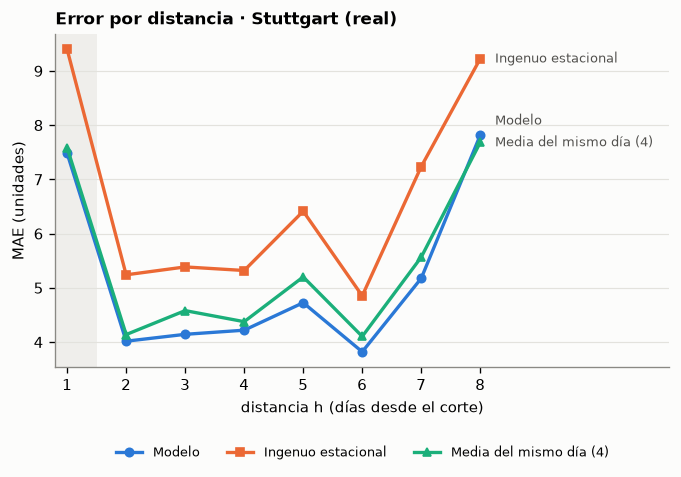

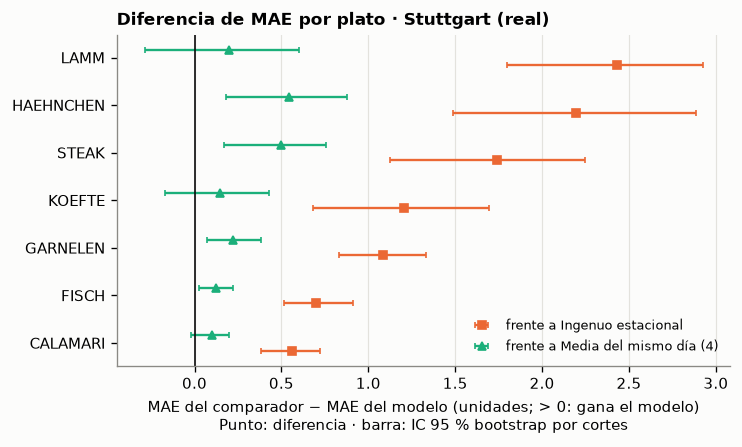

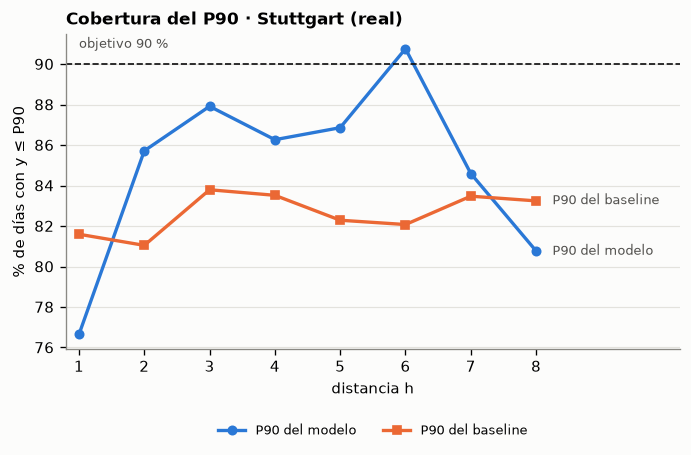

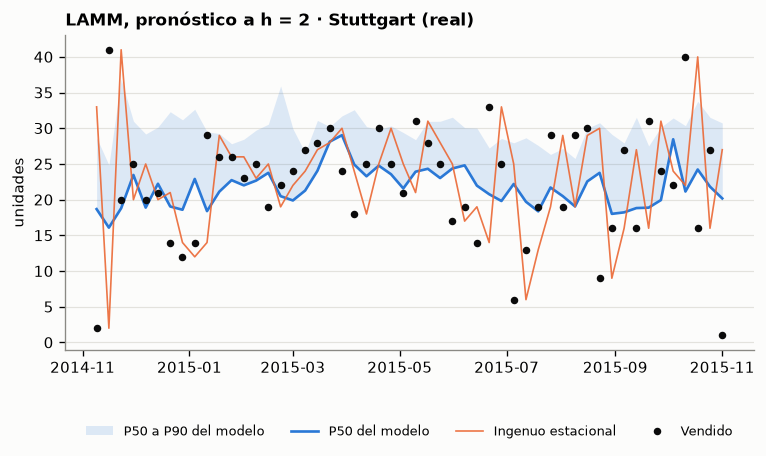

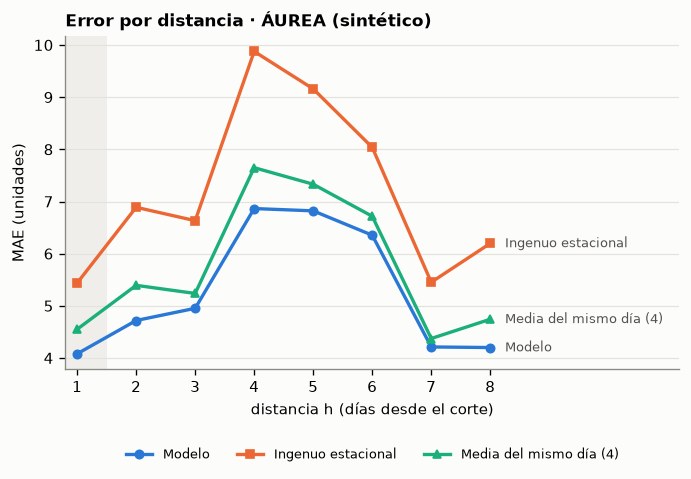

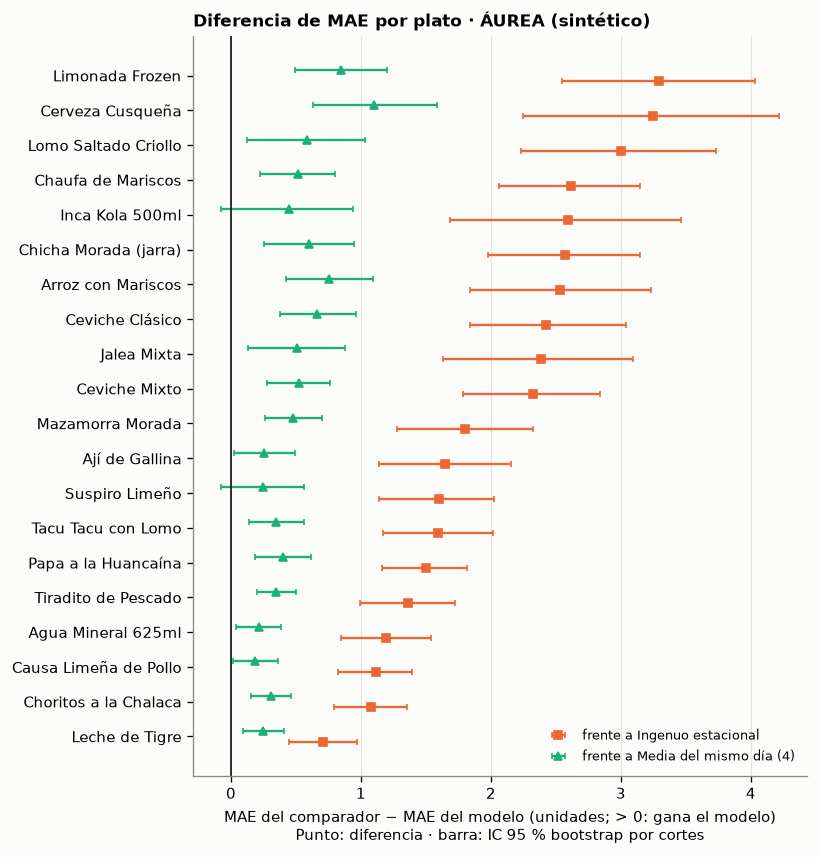

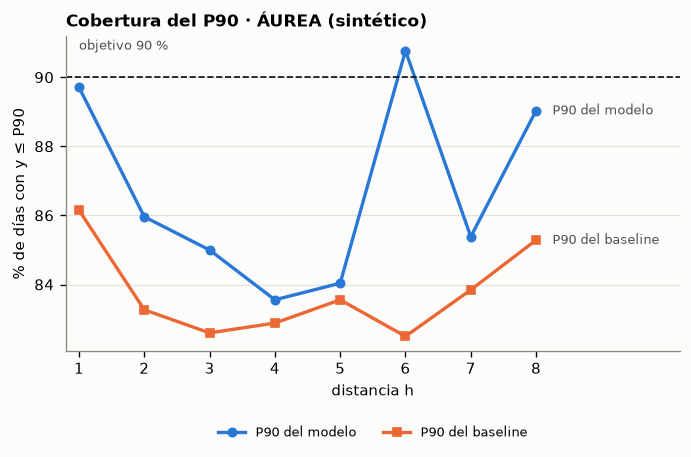

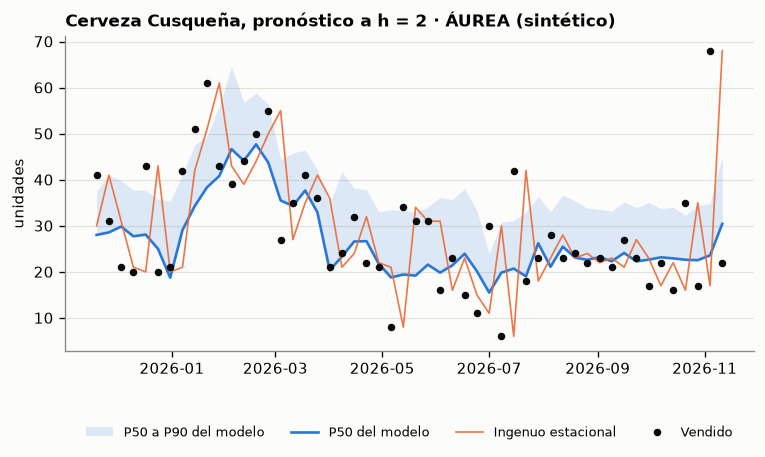

In [13]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
                     "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "grid.color": "#e3e2dd", "grid.linewidth": .7, "axes.axisbelow": True})
TINTA, TINTA2 = "#0b0b0b", "#52514e"
MARCADOR = {"modelo": "o", "ingenuo": "s", "media4": "^"}
NOMBRE_F = {"stuttgart": "Stuttgart (real)", "aurea": "ÁUREA (sintético)"}

def etiquetas_finales(ax, puntos, gap, dx=.25):
    # Etiqueta directa al final de cada serie, separadas verticalmente al menos `gap` para que no se pisen.
    orden = sorted(range(len(puntos)), key=lambda i: puntos[i][1]); ys = [puntos[i][1] for i in orden]
    for j in range(1, len(ys)): ys[j] = max(ys[j], ys[j - 1] + gap)
    for j, i in enumerate(orden):
        x, y, texto = puntos[i]; ax.text(x + dx, ys[j], texto, va="center", color=TINTA2, fontsize=8)

def leyenda_abajo(ax, ncol=3):
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.2), ncol=ncol, fontsize=8)

def guardar(fig, nombre):
    fig.savefig(FIGURAS / nombre, dpi=120, bbox_inches="tight"); plt.close(fig); display(Image(FIGURAS / nombre))

def fig_mae_por_h(f):
    t = T[f]["por_h"]; fig, ax = plt.subplots(figsize=(6.6, 3.6)); fin = []
    for k, (col, color, etiqueta) in PREDICTORES.items():
        s = t[t.predictor == etiqueta].set_index("h").MAE
        ax.plot(s.index, s.values, color=color, lw=2, marker=MARCADOR[k], ms=5, label=etiqueta)
        fin.append((s.index[-1], s.values[-1], etiqueta))
    etiquetas_finales(ax, fin, gap=.4)
    ax.set_xlim(.8, 11.2); ax.set_xticks(range(1, 9)); ax.set_xlabel("distancia h (días desde el corte)"); ax.set_ylabel("MAE (unidades)")
    ax.axvspan(.8, 1.5, color="#e3e2dd", alpha=.5, lw=0); ax.grid(axis="y"); ax.set_title(f"Error por distancia · {NOMBRE_F[f]}")
    leyenda_abajo(ax); guardar(fig, f"{f}_mae_por_h.png")

def fig_diferencia_por_plato(f):
    e = E[f]["por_plato"]; orden = e[e.comparador == PREDICTORES["ingenuo"][2]].sort_values("diferencia").plato.tolist()
    fig, ax = plt.subplots(figsize=(6.6, 1.2 + .34 * len(orden))); desplaza = {"ingenuo": -.16, "media4": .16}
    for k in ("ingenuo", "media4"):
        s = e[e.comparador == PREDICTORES[k][2]].set_index("plato").loc[orden]; y = np.arange(len(orden)) + desplaza[k]
        ax.errorbar(s.diferencia, y, xerr=[s.diferencia - s.IC95_bajo, s.IC95_alto - s.diferencia], fmt=MARCADOR[k], color=PREDICTORES[k][1],
                    ms=5, lw=1.4, capsize=2, label=f"frente a {PREDICTORES[k][2]}")
    ax.axvline(0, color=TINTA, lw=1); ax.set_yticks(range(len(orden))); ax.set_yticklabels(orden); ax.grid(axis="x")
    ax.set_xlabel("MAE del comparador − MAE del modelo (unidades; > 0: gana el modelo)\nPunto: diferencia · barra: IC 95 % bootstrap por cortes")
    ax.set_title(f"Diferencia de MAE por plato · {NOMBRE_F[f]}"); ax.legend(frameon=False, loc="lower right", fontsize=8); guardar(fig, f"{f}_diferencia_mae_por_plato.png")

def fig_cobertura(f):
    t = T[f]["por_h"]; fig, ax = plt.subplots(figsize=(6.6, 3.4)); fin = []
    for k in ("modelo", "ingenuo"):
        etiqueta = PREDICTORES[k][2]; s = t[t.predictor == etiqueta].set_index("h").cobertura_P90 * 100
        nombre = "P90 del modelo" if k == "modelo" else "P90 del baseline"
        ax.plot(s.index, s.values, color=PREDICTORES[k][1], lw=2, marker=MARCADOR[k], ms=5, label=nombre)
        fin.append((s.index[-1], s.values[-1], nombre))
    etiquetas_finales(ax, fin, gap=2.5)
    ax.axhline(90, color=TINTA, lw=1, ls="--"); ax.text(1, 90.8, "objetivo 90 %", fontsize=8, color=TINTA2)
    ax.set_xlim(.8, 10.2); ax.set_xticks(range(1, 9)); ax.set_xlabel("distancia h"); ax.set_ylabel("% de días con y ≤ P90"); ax.grid(axis="y")
    ax.set_title(f"Cobertura del P90 · {NOMBRE_F[f]}"); leyenda_abajo(ax, 2); guardar(fig, f"{f}_cobertura_p90.png")

def fig_serie(f):
    p = D[f]["pred"]; plato = p[p.h == 2].groupby("plato").y.sum().idxmax(); s = p[(p.plato == plato) & (p.h == 2)].sort_values("fecha_objetivo")
    fig, ax = plt.subplots(figsize=(7.4, 3.4))
    ax.fill_between(s.fecha_objetivo, s.p50, s.p90, color=PREDICTORES["modelo"][1], alpha=.15, lw=0, label="P50 a P90 del modelo")
    ax.plot(s.fecha_objetivo, s.p50, color=PREDICTORES["modelo"][1], lw=1.6, label="P50 del modelo")
    ax.plot(s.fecha_objetivo, s.ingenuo, color=PREDICTORES["ingenuo"][1], lw=1, alpha=.9, label="Ingenuo estacional")
    ax.plot(s.fecha_objetivo, s.y, color=TINTA, lw=0, marker="o", ms=3.5, label="Vendido")
    ax.set_ylabel("unidades"); ax.grid(axis="y"); ax.set_title(f"{plato}, pronóstico a h = 2 · {NOMBRE_F[f]}")
    leyenda_abajo(ax, 4); guardar(fig, f"{f}_serie_ejemplo.png")

for f in FUENTES:
    fig_mae_por_h(f); fig_diferencia_por_plato(f); fig_cobertura(f); fig_serie(f)

## 6. Salidas
Tablas en CSV (cifras redondeadas a 4 decimales, para que dos ejecuciones den archivos idénticos) y en Markdown.

In [14]:
def a_md(df, dec=3):
    d = df.copy()
    for c in d.columns:
        if pd.api.types.is_float_dtype(d[c]): d[c] = d[c].map(lambda v: f"{v:.{dec}f}")
    filas = ["| " + " | ".join(map(str, d.columns)) + " |", "|" + "|".join(["---"] * len(d.columns)) + "|"]
    filas += ["| " + " | ".join(map(str, r)) + " |" for r in d.astype(object).to_numpy()]
    return "\n".join(filas) + "\n"

def escribir(df, nombre):
    df = df.round(DECIMALES)
    df.to_csv(TABLAS / f"{nombre}.csv", index=False)
    (TABLAS / f"{nombre}.md").write_text(a_md(df), encoding="utf-8")

for f in FUENTES:
    for k, t in T[f].items(): escribir(t, f"{f}_metricas_{k}")
    escribir(E[f]["por_plato"], f"{f}_pruebas_por_plato"); escribir(E[f]["global"], f"{f}_pruebas_global")
escribir(V, "aurea_vs_demanda_verdadera")
sorted(p.name for p in TABLAS.iterdir())

['aurea_metricas_por_dia.csv',
 'aurea_metricas_por_dia.md',
 'aurea_metricas_por_h.csv',
 'aurea_metricas_por_h.md',
 'aurea_metricas_por_plato.csv',
 'aurea_metricas_por_plato.md',
 'aurea_metricas_total.csv',
 'aurea_metricas_total.md',
 'aurea_pruebas_global.csv',
 'aurea_pruebas_global.md',
 'aurea_pruebas_por_plato.csv',
 'aurea_pruebas_por_plato.md',
 'aurea_vs_demanda_verdadera.csv',
 'aurea_vs_demanda_verdadera.md',
 'stuttgart_metricas_por_dia.csv',
 'stuttgart_metricas_por_dia.md',
 'stuttgart_metricas_por_h.csv',
 'stuttgart_metricas_por_h.md',
 'stuttgart_metricas_por_plato.csv',
 'stuttgart_metricas_por_plato.md',
 'stuttgart_metricas_total.csv',
 'stuttgart_metricas_total.md',
 'stuttgart_pruebas_global.csv',
 'stuttgart_pruebas_global.md',
 'stuttgart_pruebas_por_plato.csv',
 'stuttgart_pruebas_por_plato.md']

## Lectura de los resultados

Cifras del escenario operativo (`h` de 2 a 8), tomadas de las tablas de arriba.

**Stuttgart (real, experimento principal).**
- **Frente al ingenuo estacional** (la referencia de la hipótesis): MAE 4,85 contra 6,24, una mejora de 22,3 % (diferencia 1,39 unidades, IC 95 % de 1,17 a 1,64). Gana en el 83 % de los pares plato × corte (Wilcoxon p < 0,001) y en los 7 platos con Diebold-Mariano y Holm.
- **Frente a la media del mismo día (4)**, el baseline más difícil: MAE 4,85 contra 5,10, una mejora de 4,8 % (diferencia 0,25; IC 95 % de 0,10 a 0,39, que no incluye el 0). Gana en el 61 % de los pares (Wilcoxon p < 0,001). Por plato, la mejora es significativa en 4 de 7 (FISCH, GARNELEN, HAEHNCHEN y STEAK); en CALAMARI, KOEFTE y LAMM la diferencia es favorable pero no significativa tras Holm.
- **Intervalo del P90:** cubre 86,1 % de los días contra 82,8 % del baseline, y su pinball es menor (1,247 contra 1,345). Mejora al baseline, pero **queda por debajo del 90 % objetivo**: el stock de seguridad `P90 − P50` sería algo corto.
- **Sesgo:** −0,81 unidades. El modelo tiende a subestimar, como es esperable en una mediana de datos con cola a la derecha.

**La distancia `h` no se puede leer sola.** Los cortes semanales caen siempre en el mismo día de la semana (viernes en Stuttgart, lunes en ÁUREA), así que `h = 1` es siempre el mismo día (en Stuttgart, el sábado, el de más demanda) y `h = 8` repite el día de `h = 1`. Por eso el error por `h` mezcla distancia y día de la semana. El escenario operativo, de 7 días consecutivos, sí cubre cada día de la semana una vez y es comparable entre predictores. En `h = 1` de Stuttgart el modelo (7,48) queda igual a la media del mismo día (7,59) y su P90 cubre solo 76,6 %; con una sola cifra por día de la semana no se puede separar cuánto es dificultad del sábado y cuánto es debilidad del modelo.

**ÁUREA (sintético, control).**
- Modelo 5,45 contra 7,47 del ingenuo (−27,0 %) y 5,93 de la media del mismo día (−8,0 %, IC 95 % de 0,31 a 0,66), con Wilcoxon p < 0,001. Frente al ingenuo gana en los 20 platos; frente a la media del mismo día mejora en los 20 y es significativo en 16 (Holm).
- **Frente a la demanda verdadera:** el modelo se acerca a la demanda esperada con MAE 2,40, la media del mismo día con 3,20 y el ingenuo con 5,51, mientras que lo vendido se aleja de lo esperado 5,09 (el piso de ruido). Es decir, el modelo recupera el patrón que escribió el generador, lo que no demuestra nada sobre restaurantes reales (D-20). También subestima la demanda esperada (sesgo −1,59).

**Alcance de estas conclusiones (D-20).** Un solo restaurante real, 7 platos, Alemania 2013-2015; la demanda está censurada por agotados; ÁUREA es sintético. La mejora sobre el ingenuo es grande y consistente; sobre la media del mismo día es pequeña y no alcanza significancia en todos los platos. La configuración se eligió en una validación de 8 semanas y quedó en una esquina de la rejilla (cuaderno 04); no se exploró más allá.


## Verificaciones

In [15]:
# 1. Cifras recalculadas a mano coinciden con las de las tablas
for f in FUENTES:
    p = op(D[f]["pred"]); fila = T[f]["total"].query("predictor == 'Modelo'").iloc[0]
    assert abs(fila.MAE - np.abs(p.p50.to_numpy() - p.y.to_numpy()).mean()) < 1e-9
    assert abs(fila.RMSE - np.sqrt(((p.p50.to_numpy() - p.y.to_numpy()) ** 2).mean())) < 1e-9
    assert abs(fila.sesgo - (p.p50 - p.y).mean()) < 1e-9
    q = pd.read_csv(TABLAS / f"{f}_metricas_total.csv"); assert abs(q.MAE[0] - fila.MAE) < 1e-4
# 2. Alcances: operativo + h=1 = todas las filas
for f in FUENTES:
    n = len(D[f]["pred"]); assert len(op(D[f]["pred"])) + len(h1(D[f]["pred"])) == n
    assert T[f]["por_h"].groupby("predictor").n.sum().eq(n).all()
# 3. Pares plato x corte: 7 platos x 52 cortes y 20 x 52
assert (E["stuttgart"]["global"].n_pares == 7 * 52).all() and (E["aurea"]["global"].n_pares == 20 * 52).all()
assert (E["stuttgart"]["por_plato"].n_cortes == 52).all()
# 4. Holm nunca baja un p; los intervalos contienen la estimación; p en [0, 1]
for f in FUENTES:
    e = E[f]["por_plato"]
    assert (e.p_Holm >= e.p_unilateral - 1e-12).all() and e.p_Holm.between(0, 1).all()
    assert ((e.IC95_bajo <= e.diferencia + 1e-9) & (e.diferencia <= e.IC95_alto + 1e-9)).all()
    g = E[f]["global"]; assert ((g.IC95_bajo <= g.diferencia) & (g.diferencia <= g.IC95_alto)).all() and g.wilcoxon_p.between(0, 1).all()
# 5. Holm contra una implementación independiente (caso conocido)
assert np.allclose(holm([0.01, 0.04, 0.03, 0.005]), [0.03, 0.06, 0.06, 0.02])
# 6. Sin NaN en las métricas y sin MAPE
for f in FUENTES:
    for t in T[f].values(): assert t.drop(columns=[c for c in t.columns if t[c].dtype == object]).notna().all().all()
    assert not any("MAPE" in c for t in T[f].values() for c in t.columns)
# 7. Archivos escritos
assert len(list(FIGURAS.glob("*.png"))) >= 8 and len(list(TABLAS.glob("*.csv"))) >= 11
print("OK · métricas y pruebas generadas")

OK · métricas y pruebas generadas
